<a href="https://colab.research.google.com/github/profhamilton3/DataAnalytics/blob/main/study_guide_pandas_describe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Study Guide: Reading `df.describe()` Like a Data Analyst

**Course:** Data Analytics Foundation (CompTIA Data+) · **Sessions:** 7 (EDA) and 8 (Descriptive Statistics) · **CompTIA Data+ DA0-002:** 3.0 Data Analysis

> One line of pandas, `df.describe()`, prints eight numbers per column. Those eight numbers answer the first questions every analyst asks about a new dataset: *How much data do I have? What is typical? How spread out is it? Is anything strange?* This study guide teaches you to read that report fluently, explains how each number is calculated, and shows why it matters, with large datasets and pictures.

### How to use this notebook in Google Colab
- **Collapse and expand sections:** click the ▸ / ▾ arrow next to any heading. Open the **Table of contents** (☰ icon, left sidebar) to jump around.
- **Run code:** click a cell and press **Shift + Enter**, from top to bottom. Each code cell starts with a `# @title`, so you can collapse the code and keep just the result.
- **Images** are built into the notebook, so nothing extra needs to download except one public dataset in the guided example.

| Section | What you will learn | Time |
|---|---|---|
| 1. The questions `describe()` answers | What each of the 8 rows tells you | 10 min |
| 2. How each number is calculated | The math, by hand and in pandas | 15 min |
| 3. Why it is the analyst's first glance | Where, when and why it matters | 10 min |
| 4. Three worked examples | Skewed salaries, delivery risk, sensor data quality | 25 min |
| 5. Guided hands-on: 53,940 diamonds | Step-by-step analysis with conclusions | 25 min |
| 6. Check your understanding | 10 auto-scored questions | 10 min |
| 7. Lesson summary | Cheat sheet | 5 min |

In [1]:
# @title Setup: import libraries and set a clean, colorblind-friendly chart style
import numpy as np                 # numbers and random data
import pandas as pd                # DataFrames and describe()
import matplotlib.pyplot as plt    # charts
import seaborn as sns              # nicer statistical charts

sns.set_theme(style="whitegrid")
# Okabe-Ito colors: readable for people with color-vision deficiency
BLUE, ORANGE, GREEN, RED, SKY, GREY = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#56B4E9", "#9AA0A6"
pd.set_option("display.float_format", "{:,.2f}".format)   # show 2 decimals with thousands separators
print("Ready! pandas", pd.__version__)

Ready! pandas 2.2.3


## 1. What questions does `describe()` answer?

`df.describe()` returns a **summary table**: one column per numeric column of your data, and eight rows. Each row answers a specific question.

| Row | The question it answers | Plain-English meaning |
|---|---|---|
| **count** | *How many values do I actually have?* | Number of **non-missing** values. Compare it with `len(df)` to find missing data. |
| **mean** | *What is the average?* | Sum of values ÷ count. The "fair share" if everything were split evenly. |
| **std** | *How spread out are the values?* | Standard deviation: the typical distance of a value from the mean. |
| **min** | *What is the smallest value?* | First sanity check: negative ages? zero prices? error codes? |
| **25%** | *Where does the bottom quarter end?* | First quartile (Q1): 25% of values are at or below this. |
| **50%** | *What is the middle value?* | The **median**. Half the values are below, half above. Not fooled by outliers. |
| **75%** | *Where does the top quarter begin?* | Third quartile (Q3): 75% of values are at or below this. |
| **max** | *What is the largest value?* | Second sanity check: impossible highs? extreme outliers? |

Together they describe the **center** (mean, 50%), the **spread** (std, 25%, 75%, min, max) and the **completeness** (count) of every column.

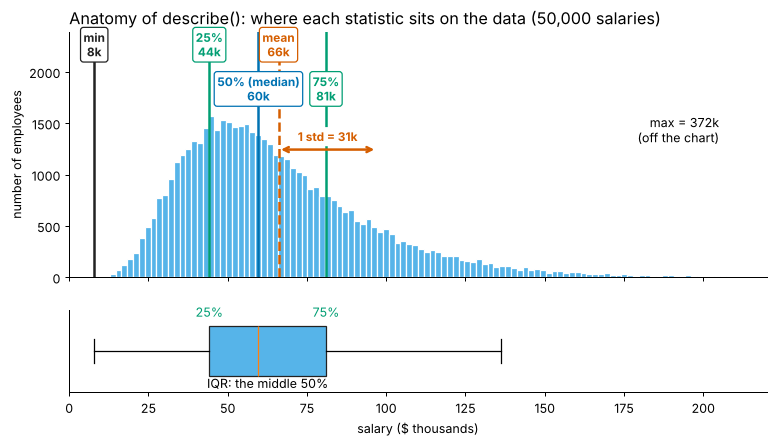

*Picture: the eight statistics placed on real data. Notice the mean (dashed red) sits to the right of the median (blue): a long tail of high salaries pulls the average up.*

In [2]:
# @title See it: describe() on 50,000 salaries
rng = np.random.default_rng(7)                       # fixed seed: everyone gets identical data
n = 50_000
salaries = pd.DataFrame({
    "salary": np.round(rng.lognormal(mean=11.0, sigma=0.45, size=n), -2),    # right-skewed, like real pay
    "years_experience": np.clip(np.round(rng.gamma(shape=3, scale=3, size=n)), 0, 40),
})

summary = salaries.describe()     # one line, eight answers per column
summary

,salary,years_experience
count,"50,000.00","50,000.00"
mean,"66,028.09",8.99
std,"30,996.90",5.20
min,"7,900.00",0.00
25%,"44,200.00",5.00
50%,"59,700.00",8.00
75%,"81,000.00",12.00
max,"372,400.00",40.00


**Read it like an analyst:**
- **count = 50,000** for both columns, the same as the number of rows, so **no missing values**.
- **mean (66,028) > 50% (59,700)** → a few large salaries pull the average up (right skew). The median is the better "typical salary."
- **std = 30,997** → salaries typically sit about $30,997 away from the average.
- **25% to 75% = 44,200 to 81,000** → the middle half of employees earn in this range.
- **max = 372,400** is far above the 75% mark → there are high-earning outliers worth investigating.

## 2. How each number is calculated

Knowing the formula tells you what each number *can* and *cannot* show you.

### 2.1 count, mean, min and max
- **count** = number of values that are **not** `NaN` (missing). Missing values are skipped everywhere in `describe()`.
- **mean** $\bar{x} = \dfrac{\sum x_i}{n}$ : add every value, divide by the count. **Sensitive to outliers:** one huge value moves it.
- **min / max** = the smallest and largest values after skipping missing ones.

### 2.2 std: the standard deviation
$$s = \sqrt{\dfrac{\sum (x_i - \bar{x})^2}{n - 1}}$$

In words: (1) measure each value's distance from the mean, (2) square the distances so negatives don't cancel positives, (3) average them, dividing by **n − 1**, and (4) take the square root to get back to the original units.

⚠️ **pandas divides by n − 1** (the *sample* standard deviation, `ddof=1`) because your data is usually a sample of a bigger population. NumPy's `np.std()` divides by **n** by default, so the two can differ slightly. On big datasets the difference is tiny; on small ones it matters.

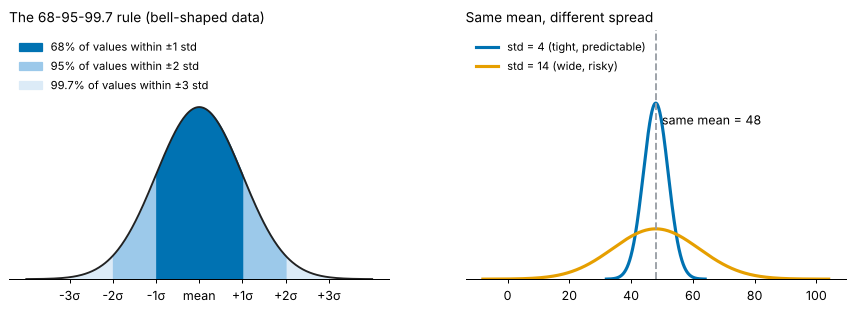

*Picture: for bell-shaped data, about 68% of values fall within 1 std of the mean, 95% within 2, and 99.7% within 3. Two datasets can share a mean but have very different spreads.*

### 2.3 The percentiles: 25%, 50%, 75%
1. **Sort** the values from smallest to largest.
2. Find the **position** = (n − 1) × p, counting from 0 (p = 0.25, 0.50 or 0.75).
3. If the position lands between two values, pandas **interpolates** (takes the point that far between them). This is called *linear interpolation*.

The distance **75% − 25%** is the **IQR (interquartile range)**: the width of the middle 50% of your data. Box plots draw it as the box, and the **1.5 × IQR rule** (Session 7) uses it to flag outliers.


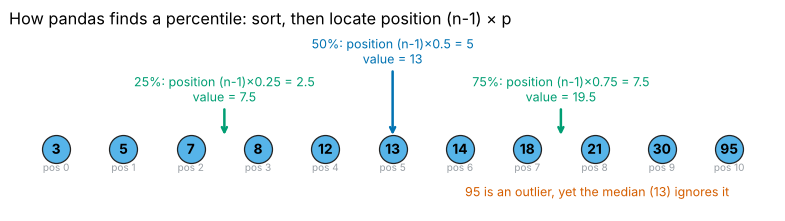

In [3]:
# @title Prove it: calculate every describe() number by hand, then compare with pandas
# A tiny dataset so you can check the math on paper
values = pd.Series([3, 5, 7, 8, 12, 13, 14, 18, 21, 30, 95], name="value")

n = values.count()                                    # count: non-missing values
mean = values.sum() / n                               # mean: sum ÷ count
std = np.sqrt(((values - mean) ** 2).sum() / (n - 1)) # sample std: divide by n - 1
srt = values.sort_values().to_numpy()                 # percentiles start by sorting

def percentile(sorted_vals, p):
    pos = (len(sorted_vals) - 1) * p                  # position counted from 0
    lo, hi = int(np.floor(pos)), int(np.ceil(pos))
    return sorted_vals[lo] + (sorted_vals[hi] - sorted_vals[lo]) * (pos - lo)   # linear interpolation

by_hand = pd.Series({"count": n, "mean": mean, "std": std, "min": srt[0],
                     "25%": percentile(srt, .25), "50%": percentile(srt, .5),
                     "75%": percentile(srt, .75), "max": srt[-1]}, name="by hand")

comparison = pd.concat([by_hand, values.describe().rename("pandas describe()")], axis=1)
comparison["match?"] = np.isclose(comparison["by hand"], comparison["pandas describe()"])
print("Population std (np.std, divides by n):    ", round(np.std(values), 2))
print("Sample std (pandas, divides by n - 1):     ", round(values.std(), 2))
comparison

Population std (np.std, divides by n):     24.68
Sample std (pandas, divides by n - 1):      25.89


,by hand,pandas describe(),match?
count,11.00,11.00,True
mean,20.55,20.55,True
std,25.89,25.89,True
min,3.00,3.00,True
25%,7.50,7.50,True
50%,13.00,13.00,True
75%,19.50,19.50,True
max,95.00,95.00,True


Every row matches. Notice how the single outlier (**95**) drags the **mean** far above the **median (13)** and inflates the **std**. That is exactly what you will spot in real data.

## 3. Why `describe()` is the analyst's first glance

**When:** immediately after loading any dataset, and again after every cleaning step, join or filter. **Where:** Python/pandas, but the same eight numbers exist in SQL (`COUNT`, `AVG`, `STDDEV`, `MIN`, `MAX`, `PERCENTILE_CONT`), R (`summary()`), Excel and SPSS (*Descriptives*). **Why:** it costs one line and catches problems before they become wrong conclusions in front of your boss.

| You see... | It usually means... | Your next move |
|---|---|---|
| `count` < number of rows | Missing values | Find out why before analyzing (Session 5) |
| `min`/`max` impossible (−999, age 230) | Data-entry errors or error codes | Investigate the source system |
| `mean` far from `50%` | Skewed data or outliers | Report the median; consider a log scale |
| `std` larger than the `mean` | Very spread out, maybe mixed groups | Split by category with `groupby().describe()` |
| `max` far above `75%` | Long tail / outliers | Apply the 1.5 × IQR rule (Session 7) |
| `25%` = `50%` = `75%` | Many repeated values | Check for default values or rounding |

**On the CompTIA Data+ exam (Domain 3.0)** you are expected to choose the right measure of center and spread, recognize skew from mean vs. median, and explain variance and standard deviation.


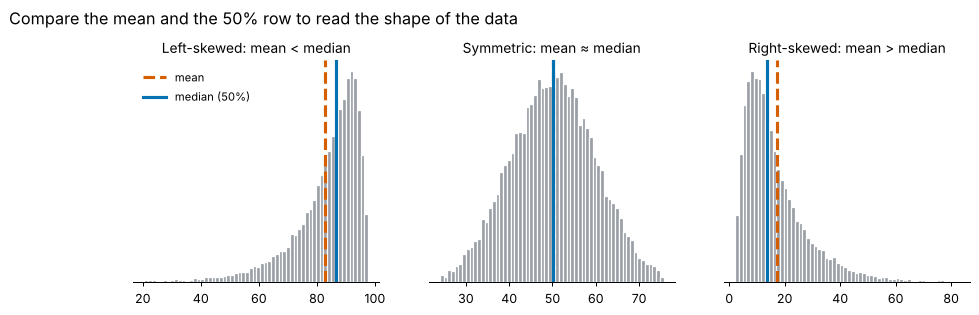

In [4]:
# @title Useful variations: custom percentiles, text columns, transposing and grouping
# Reuses the salaries data from Section 1 (run that cell first)
salaries["band"] = pd.cut(salaries["years_experience"], bins=[-1, 2, 7, 15, 40],
                          labels=["0-2 yrs", "3-7 yrs", "8-15 yrs", "16+ yrs"])

print("1) Extra percentiles: what do the top 10% and top 1% earn?")
display(salaries["salary"].describe(percentiles=[.10, .25, .5, .75, .90, .99]))

print("2) Text/categorical columns get count, unique, top (most common) and freq:")
display(salaries[["band"]].describe())

print("3) describe() per group: transpose (.T) so each group is one easy-to-read row")
display(salaries.groupby("band", observed=True)["salary"].describe().round(0))

1) Extra percentiles: what do the top 10% and top 1% earn?


,salary
count,"50,000.00"
mean,"66,028.09"
std,"30,996.90"
min,"7,900.00"
10%,"33,600.00"
25%,"44,200.00"
50%,"59,700.00"
75%,"81,000.00"
90%,"106,200.00"
99%,"168,000.00"


2) Text/categorical columns get count, unique, top (most common) and freq:


,band
count,50000
unique,4
top,8-15 yrs
freq,21563


3) describe() per group: transpose (.T) so each group is one easy-to-read row


,count,mean,std,min,25%,50%,75%,max
band,,,,,,,,
0-2 yrs,"2,564.00","64,998.00","30,675.00","11,200.00","43,500.00","59,000.00","80,100.00","285,600.00"
3-7 yrs,"20,328.00","65,756.00","30,641.00","11,500.00","44,200.00","59,700.00","80,800.00","323,300.00"
8-15 yrs,"21,563.00","66,130.00","31,137.00","7,900.00","44,100.00","59,600.00","80,900.00","345,600.00"
16+ yrs,"5,545.00","67,102.00","31,865.00","12,900.00","44,700.00","60,300.00","82,200.00","372,400.00"


## 4. Three worked examples

Each example is its own collapsible section. Run the cells in order inside each one.

### Example 1: Skewed salaries. Mean or median?
**Business question:** HR wants to advertise a "typical salary." Which number from `describe()` should they use?

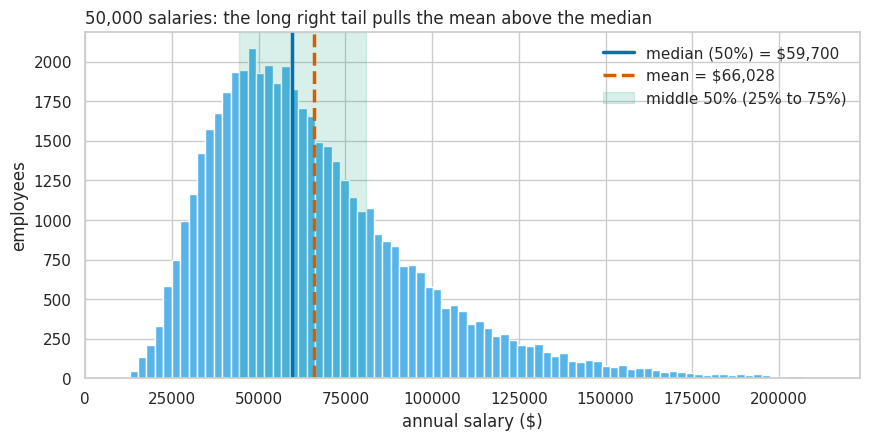

The mean is 10.6% higher than the median.
Share of employees who earn LESS than the mean: 59%


In [5]:
# @title Example 1: histogram with the describe() numbers drawn on it
s = salaries["salary"]
d = s.describe()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(s, bins=150, color=SKY, edgecolor="white")
ax.axvline(d["50%"], color=BLUE, lw=2.5, label=f"median (50%) = ${d['50%']:,.0f}")
ax.axvline(d["mean"], color=RED, lw=2.5, ls="--", label=f"mean = ${d['mean']:,.0f}")
ax.axvspan(d["25%"], d["75%"], color=GREEN, alpha=0.15, label="middle 50% (25% to 75%)")
ax.set_xlim(0, d["max"] * 0.6)
ax.set_title("50,000 salaries: the long right tail pulls the mean above the median", loc="left")
ax.set_xlabel("annual salary ($)"); ax.set_ylabel("employees"); ax.legend(frameon=False)
plt.show()

gap = (d["mean"] - d["50%"]) / d["50%"] * 100
print(f"The mean is {gap:.1f}% higher than the median.")
print(f"Share of employees who earn LESS than the mean: {(s < d['mean']).mean():.0%}")

**Conclusion:** the mean (66,028) is about 11% above the median (59,700), and roughly 59% of employees earn less than the "average." **Advertise the median.** This is the classic CompTIA scenario: *use the median for skewed data such as salaries and home prices.*

### Example 2: Same average, different risk. Why `std` matters
**Business question:** two warehouses both deliver in **48 hours on average**. Which one should get the priority-customer contract?

In [6]:
# @title Example 2: compare two warehouses with describe() side by side
rng = np.random.default_rng(11)
n = 20_000
deliveries = pd.DataFrame({
    "warehouse_A": np.clip(rng.normal(loc=48, scale=4,  size=n), 2, None).round(1),   # consistent
    "warehouse_B": np.clip(rng.normal(loc=48, scale=14, size=n), 2, None).round(1),   # same average, much less predictable
})

deliveries.describe()

,warehouse_A,warehouse_B
count,"20,000.00","20,000.00"
mean,48.01,47.98
std,3.99,14.01
min,33.20,2.00
25%,45.30,38.70
50%,48.00,48.00
75%,50.70,57.60
max,63.30,116.20


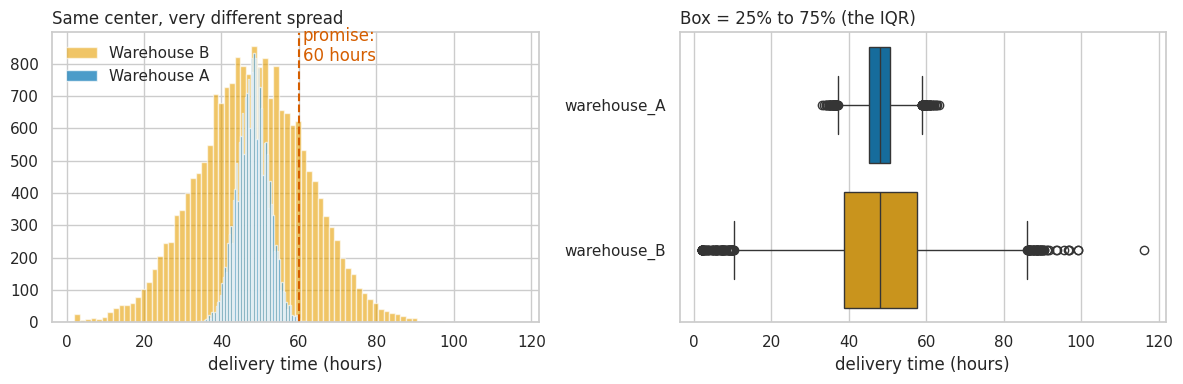

Deliveries later than 60 hours: A = 0.1%   B = 19.6%


In [8]:
# @title Example 2: visualize the spread with histograms and box plots
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.hist(deliveries["warehouse_B"], bins=80, alpha=0.6, color=ORANGE, label="Warehouse B")
a1.hist(deliveries["warehouse_A"], bins=80, alpha=0.7, color=BLUE, label="Warehouse A")
a1.axvline(60, color=RED, ls="--"); a1.text(61, a1.get_ylim()[1] * 0.9, "promise:\n60 hours", color=RED)
a1.set_title("Same center, very different spread", loc="left"); a1.set_xlabel("delivery time (hours)"); a1.legend(frameon=False)
sns.boxplot(data=deliveries, orient="h", ax=a2, palette=[BLUE, ORANGE])
a2.set_title("Box = 25% to 75% (the IQR)", loc="left"); a2.set_xlabel("delivery time (hours)")
plt.tight_layout(); plt.show()

late = (deliveries > 60).mean() * 100
print(f"Deliveries later than 60 hours: A = {late['warehouse_A']:.1f}%   B = {late['warehouse_B']:.1f}%")

**Conclusion:** the means are nearly identical (48.0 vs 48.0 hours), but warehouse B's **std (14.0)** is more than three times A's **(4.0)**. B's middle 50% stretches from 38.7 to 57.6 hours, and **19.6%** of its deliveries miss a 60-hour promise, versus **0.11%** for A. **Give the contract to A.** *An average alone hides risk; the standard deviation and quartiles reveal it.*

### Example 3: The data-quality first glance. Reading `count`, `min` and `max`
**Business question:** a factory streams machine temperatures. Before building a dashboard, is the data trustworthy?

In [9]:
# @title Example 3: describe() on 30,000 sensor readings
rng = np.random.default_rng(21)
n = 30_000
temps = rng.normal(loc=72, scale=3, size=n).round(1)            # a healthy machine runs near 72 F
temps[rng.choice(n, size=1_500, replace=False)] = np.nan          # 5% of readings never arrived (sensor dropouts)
temps[rng.choice(n, size=40, replace=False)] = -999.0             # an error code the sensor writes when it fails
sensors = pd.DataFrame({"temp_f": temps})

print("Rows in the table:", len(sensors))
sensors.describe()

Rows in the table: 30000


,temp_f
count,"28,502.00"
mean,70.50
std,40.21
min,-999.00
25%,70.00
50%,72.00
75%,74.00
max,84.40


count is 28,502 but there are 30,000 rows -> 1,498 readings are MISSING (5%).
min is -999 F -> impossible for a running machine. Looks like an error code.
How many -999 readings? 40


,all readings,plausible readings only
count,"28,502.00","28,462.00"
mean,70.50,72.01
std,40.21,2.98
min,-999.00,59.50
25%,70.00,70.00
50%,72.00,72.00
75%,74.00,74.00
max,84.40,84.40


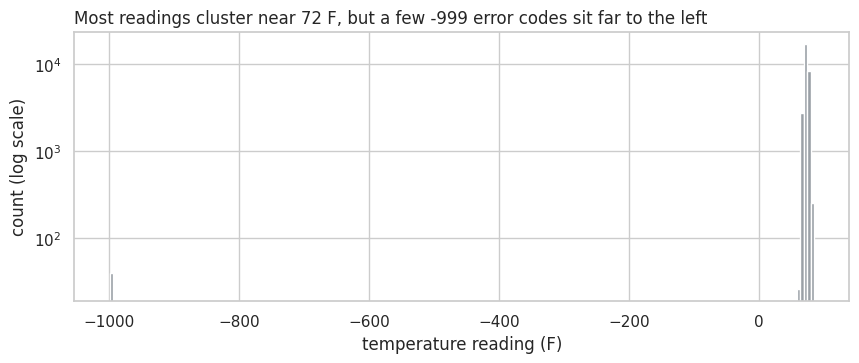

In [10]:
# @title Example 3: what count, min and the mean are telling us
d = sensors["temp_f"].describe()
missing = len(sensors) - d["count"]
print(f"count is {d['count']:,.0f} but there are {len(sensors):,} rows -> {missing:,.0f} readings are MISSING ({missing/len(sensors):.0%}).")
print(f"min is {d['min']:,.0f} F -> impossible for a running machine. Looks like an error code.")
print(f"How many -999 readings? {(sensors['temp_f'] == -999).sum()}")

# Compare: what describe() would say if we only look at plausible readings
plausible = sensors.loc[sensors["temp_f"] > -100, "temp_f"]
compare = pd.concat([d.rename("all readings"), plausible.describe().rename("plausible readings only")], axis=1)
display(compare)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(sensors["temp_f"].dropna(), bins=200, color=GREY)
ax.set_title("Most readings cluster near 72 F, but a few -999 error codes sit far to the left", loc="left")
ax.set_xlabel("temperature reading (F)"); ax.set_yscale("log"); ax.set_ylabel("count (log scale)")
plt.show()

**Conclusion:** three warning signs in one table. **count** (28,502) is lower than the 30,000 rows, so 5% of readings are missing. **min = −999** is an error code, not a temperature. Those 40 bad values drag the **mean** down to 70.5 °F and blow the **std** up to 40.2 (the plausible readings average 72.0 °F with a std of only 3.0). Notice the **median (72.0)** barely moved: it resists outliers. *Never trust a mean until you have checked count, min and max.* Report the issues to the data owner before building anything (Session 5).

## 5. 🧭 Guided hands-on: 53,940 diamonds, step by step

You are an analyst for an online jewelry retailer. The dataset is clean (no cleanup needed), so you can focus purely on **statistical analysis**. Work through each step: **predict** what you expect, **run** the cell, then open **"Guided conclusion"** to check your thinking.

Columns used: `price` (US dollars), `carat` (weight), `cut` (Fair, Good, Very Good, Premium, Ideal).

In [11]:
# @title Step 1: load the data and check its size
diamonds = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv")
print("Rows, columns:", diamonds.shape)
diamonds.head()

Rows, columns: (53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.50,55.00,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.80,61.00,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.90,65.00,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.40,58.00,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.30,58.00,335,4.34,4.35,2.75


### Step 2: Run `describe()` and read the `count` row
🤔 **Predict:** if a column had missing values, what would you see in the count row?

In [12]:
# @title Step 2: describe() for every numeric column
diamonds.describe()

,carat,depth,table,price,x,y,z
count,"53,940.00","53,940.00","53,940.00","53,940.00","53,940.00","53,940.00","53,940.00"
mean,0.80,61.75,57.46,"3,932.80",5.73,5.73,3.54
std,0.47,1.43,2.23,"3,989.44",1.12,1.14,0.71
min,0.20,43.00,43.00,326.00,0.00,0.00,0.00
25%,0.40,61.00,56.00,950.00,4.71,4.72,2.91
50%,0.70,61.80,57.00,"2,401.00",5.70,5.71,3.53
75%,1.04,62.50,59.00,"5,324.25",6.54,6.54,4.04
max,5.01,79.00,95.00,"18,823.00",10.74,58.90,31.80


<details><summary><b>💡 Guided conclusion</b></summary>

Every column shows **count = 53,940**, the same as the number of rows, so there are **no missing values**. We can trust that every statistic is based on all 53,940 diamonds. (Also notice **min = 0** for the `x`, `y`, `z` dimensions: a few diamonds have a recorded size of zero, which a real analyst would flag. We leave them alone in this lesson.)
</details>

### Step 3: Center. Is the "average diamond price" typical?
🤔 **Predict:** for prices, will the mean be above or below the median?

In [13]:
# @title Step 3: compare the mean and the median for price
price = diamonds["price"].describe()
print(f"mean price:   ${price['mean']:,.0f}")
print(f"median price: ${price['50%']:,.0f}")
print(f"The mean is {price['mean'] / price['50%']:.2f} times the median")

mean price:   $3,933
median price: $2,401
The mean is 1.64 times the median


<details><summary><b>💡 Guided conclusion</b></summary>

The mean (**$3,933**) is about **1.6 times** the median (**$2,401**). That is strong **right skew**: a minority of very expensive diamonds pulls the average up. Half of all diamonds cost **$2,401 or less**, so the median is the honest "typical price."
</details>

### Step 4: Spread. How varied are prices?

In [14]:
# @title Step 4: std, IQR and the coefficient of variation
iqr = price["75%"] - price["25%"]
cv = price["std"] / price["mean"] * 100          # coefficient of variation: spread relative to the mean
print(f"std:  ${price['std']:,.0f}")
print(f"middle 50% of prices: ${price['25%']:,.0f} to ${price['75%']:,.0f}  (IQR = ${iqr:,.0f})")
print(f"coefficient of variation: {cv:.0f}% of the mean")

std:  $3,989
middle 50% of prices: $950 to $5,324  (IQR = $4,374)
coefficient of variation: 101% of the mean


<details><summary><b>💡 Guided conclusion</b></summary>

The std (**$3,989**) is about **101%** of the mean, which is very high variation. The middle half of diamonds costs between **$950** and **$5,324** (IQR ≈ $4,374). The catalog really serves two markets: affordable everyday pieces and a luxury tail.
</details>

### Step 5: See it. Draw the describe() numbers on the distribution

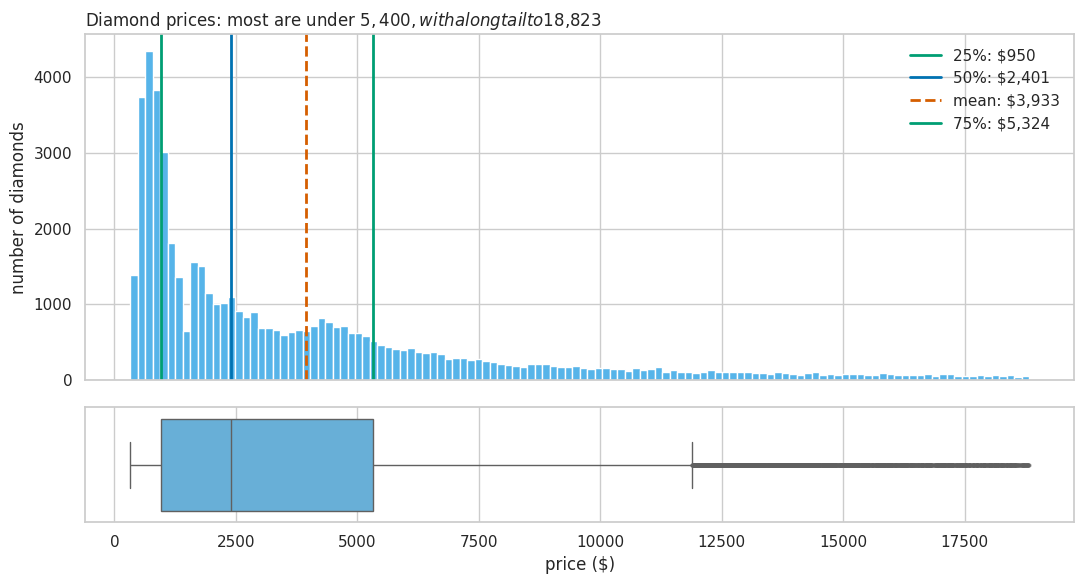

In [15]:
# @title Step 5: histogram and box plot of price with the quartiles marked
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
a1.hist(diamonds["price"], bins=120, color=SKY, edgecolor="white")
for stat, color, style in [("25%", GREEN, "-"), ("50%", BLUE, "-"), ("mean", RED, "--"), ("75%", GREEN, "-")]:
    a1.axvline(price[stat], color=color, ls=style, lw=2, label=f"{stat}: ${price[stat]:,.0f}")
a1.legend(frameon=False); a1.set_ylabel("number of diamonds")
a1.set_title("Diamond prices: most are under $5,400, with a long tail to $18,823", loc="left")
sns.boxplot(x=diamonds["price"], ax=a2, color=SKY, flierprops=dict(markersize=2, alpha=0.3))
a2.set_xlabel("price ($)")
plt.tight_layout(); plt.show()

<details><summary><b>💡 Guided conclusion</b></summary>

The picture confirms the numbers: a tall pile on the left, a long thin tail to the right, and the dashed mean line sitting to the right of the median. The box plot's dots beyond the right whisker are the high-price outliers the **max ($18,823)** warned us about.
</details>

### Step 6: Zoom into the top end with custom percentiles

In [16]:
# @title Step 6: what do the top 10% and top 1% of diamonds cost?
diamonds["price"].describe(percentiles=[.10, .25, .50, .75, .90, .99]).round(0)

,price
count,"53,940.00"
mean,"3,933.00"
std,"3,989.00"
min,326.00
10%,646.00
25%,950.00
50%,"2,401.00"
75%,"5,324.00"
90%,"9,821.00"
99%,"17,378.00"


<details><summary><b>💡 Guided conclusion</b></summary>

The **99th percentile is about $17,378**: only 1 diamond in 100 costs more. Custom percentiles answer business questions that the standard five-number summary can't, such as "what price should define our luxury tier?"
</details>

### Step 7: Compare groups. Does a better cut mean a higher price?
🤔 **Predict:** "Ideal" is the best cut. Should it have the highest median price?

In [17]:
# @title Step 7: describe() price for each cut
order = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
by_cut = diamonds.groupby("cut")["price"].describe().loc[order]
by_cut[["count", "mean", "25%", "50%", "75%"]].round(0)

,count,mean,25%,50%,75%
cut,,,,,
Fair,"1,610.00","4,359.00","2,050.00","3,282.00","5,206.00"
Good,"4,906.00","3,929.00","1,145.00","3,050.00","5,028.00"
Very Good,"12,082.00","3,982.00",912.00,"2,648.00","5,373.00"
Premium,"13,791.00","4,584.00","1,046.00","3,185.00","6,296.00"
Ideal,"21,551.00","3,458.00",878.00,"1,810.00","4,678.00"


<details><summary><b>💡 Guided conclusion</b></summary>

Surprise: **Ideal** diamonds have the **lowest median price ($1,810)**, while **Premium** (3,185) and **Fair** (3,282) are much higher. Better cut does *not* mean higher price on its own. Something else is going on. Step 8 finds it.
</details>

,mean,50%
cut,,
Fair,1.05,1.00
Good,0.85,0.82
Very Good,0.81,0.71
Premium,0.89,0.86
Ideal,0.70,0.54


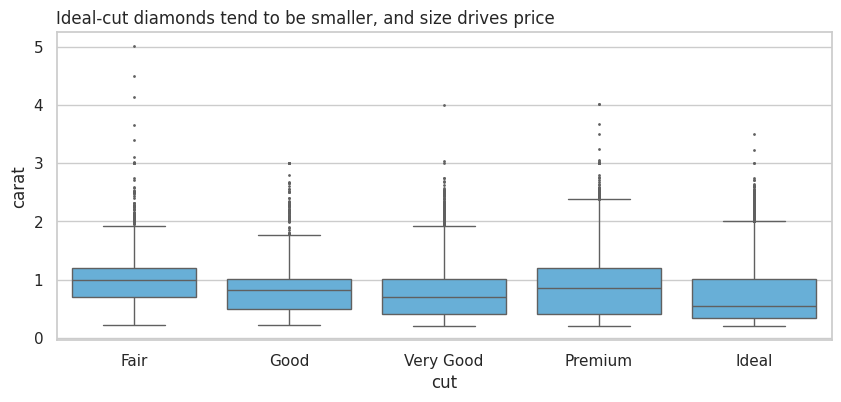

In [18]:
# @title Step 8: the hidden factor. describe() carat (size) for each cut
carat_by_cut = diamonds.groupby("cut")["carat"].describe().loc[order]
display(carat_by_cut[["mean", "50%"]].round(2))

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=diamonds, x="cut", y="carat", order=order, color=SKY, ax=ax, fliersize=1)
ax.set_title("Ideal-cut diamonds tend to be smaller, and size drives price", loc="left")
plt.show()

<details><summary><b>💡 Guided conclusion</b></summary>

The median **Ideal** diamond weighs only **0.54 carat**, versus **0.86** for Premium and **1.00** for Fair. **Carat (size) is the hidden driver of price.** Ideal cuts are typically smaller stones, so their prices look lower. This is a *confounding variable*: when comparing groups with `describe()`, always ask "what else differs between these groups?"
</details>

### ✅ Final conclusions for the retailer
1. **No missing data** (count = 53,940 everywhere), so the statistics are trustworthy.
2. **Report the median price ($2,401)**, not the mean ($3,933): prices are strongly right-skewed.
3. **Two markets:** the middle half of diamonds costs $950 to $5,324, with a luxury tail (top 1% above about $17,378).
4. **Cut alone does not explain price.** Size (carat) does. Compare like with like before drawing conclusions.

## 6. ✅ Check your understanding (10 questions, auto-scored)

Run the cell below, choose an answer for each question, then click **Check my answers**. You get your score and an explanation for every question. Click **Try again** to reset.

*If the buttons don't appear in Colab, run the cell once more.*

In [19]:
# @title Quiz: 10 auto-scored questions (run me, then answer)
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Each question: (question, [options], index of correct option, explanation)
QUESTIONS = [
    ("df has 10,000 rows, but describe() shows count = 9,400 for the 'age' column. What does that mean?", ['600 ages are zero', '600 ages are missing (NaN)', '600 ages are duplicates', '600 ages are outliers'], 1, 'count only counts non-missing values. 10,000 − 9,400 = 600 missing values.'),
    ('For a column of house prices, the mean is $480,000 and the 50% value is $350,000. What is the most likely shape?', ['Symmetric', 'Left-skewed', 'Right-skewed', 'Uniform'], 2, 'A mean well above the median means a long right tail of expensive homes pulls the average up.'),
    ('Which row of describe() is the median?', ['mean', '25%', '50%', '75%'], 2, 'The 50th percentile is the median: half of the values are below it and half are above.'),
    ('What does the std row measure?', ['The most common value', 'The middle value', 'The number of unique values', 'The typical distance of values from the mean'], 3, 'Standard deviation measures spread: how far values typically sit from the mean.'),
    ('How do you calculate the IQR from describe() output?', ['75% − 25%', 'max − min', 'mean − 50%', 'std × 2'], 0, 'The interquartile range is Q3 − Q1, the width of the middle 50% of the data.'),
    ("describe() shows min = -999 for a 'temperature' column. What is the best first step?", ['Report the mean as-is', 'Delete the whole column', 'Investigate it as a likely error code or bad data', 'Use the max instead'], 2, 'An impossible minimum is a data-quality red flag. Investigate the source before trusting any statistic.'),
    ('Two stores both average 100 sales a day. Store A has std = 5 and Store B has std = 40. Which statement is true?', ['Store B is more consistent', 'They are equally risky', 'Store B sells more on average', 'Store A is more predictable'], 3, 'Same mean, smaller std = values cluster tightly = more predictable sales.'),
    ("pandas' std() divides by n − 1, not n. Why?", ['It gives the sample standard deviation, a better estimate for a population', 'It is a rounding trick', 'It removes outliers', 'It ignores missing values'], 0, "Dividing by n − 1 (ddof=1) corrects the bias when you estimate a population's spread from a sample."),
    ('Which code adds the 90th and 99th percentiles to the report?', ['df.describe(percentiles=[.9, .99])', "df.describe(include='all')", 'df.quantile()', 'df.describe().T'], 0, 'The percentiles parameter adds extra rows to describe(). (The 50% median is always included.)'),
    ('Which measure of center is LEAST affected by a few extreme outliers?', ['mean', 'max', '50% (median)', 'std'], 2, 'The median only depends on the middle position, so extreme values barely move it.')
]

pickers = []
for i, (q, opts, correct, why) in enumerate(QUESTIONS, 1):
    display(HTML(f"<p style='margin:14px 0 4px'><b>{i}. {q}</b></p>"))
    rb = widgets.RadioButtons(options=opts, value=None, layout=widgets.Layout(width="max-content"))
    pickers.append(rb)
    display(rb)

check = widgets.Button(description="Check my answers", button_style="primary", icon="check")
reset = widgets.Button(description="Try again", icon="refresh")
result = widgets.Output()

def grade(_):
    with result:
        clear_output()
        score = 0
        for i, (rb, (q, opts, correct, why)) in enumerate(zip(pickers, QUESTIONS), 1):
            right = rb.value == opts[correct]
            score += right
            mark = "✅ Correct" if right else ("⚠️ Not answered" if rb.value is None else "❌ Not quite")
            display(HTML(f"<p><b>Q{i}: {mark}.</b> Answer: <i>{opts[correct]}</i>. {why}</p>"))
        verdict = "Excellent! You read describe() like a pro." if score >= 9 else ("Good work. Review the questions you missed." if score >= 7 else "Re-read Sections 1-3, then try again.")
        display(HTML(f"<h3>Your score: {score} / {len(QUESTIONS)} ({score/len(QUESTIONS):.0%}). {verdict}</h3>"))

def start_over(_):
    for rb in pickers:
        rb.value = None
    with result:
        clear_output()

check.on_click(grade)
reset.on_click(start_over)
display(widgets.HBox([check, reset]), result)

RadioButtons(layout=Layout(width='max-content'), options=('600 ages are zero', '600 ages are missing (NaN)', '…

RadioButtons(layout=Layout(width='max-content'), options=('Symmetric', 'Left-skewed', 'Right-skewed', 'Uniform…

RadioButtons(layout=Layout(width='max-content'), options=('mean', '25%', '50%', '75%'), value=None)

RadioButtons(layout=Layout(width='max-content'), options=('The most common value', 'The middle value', 'The nu…

RadioButtons(layout=Layout(width='max-content'), options=('75% − 25%', 'max − min', 'mean − 50%', 'std × 2'), …

RadioButtons(layout=Layout(width='max-content'), options=('Report the mean as-is', 'Delete the whole column', …

RadioButtons(layout=Layout(width='max-content'), options=('Store B is more consistent', 'They are equally risk…

RadioButtons(layout=Layout(width='max-content'), options=('It gives the sample standard deviation, a better es…

RadioButtons(layout=Layout(width='max-content'), options=('df.describe(percentiles=[.9, .99])', "df.describe(i…

RadioButtons(layout=Layout(width='max-content'), options=('mean', 'max', '50% (median)', 'std'), value=None)

Output()

## 7. 📝 Lesson summary

`df.describe()` is the analyst's **first glance**: one line that summarizes the **completeness, center and spread** of every numeric column.

| Row | Answers | Watch for |
|---|---|---|
| count | How many real values? | count < rows → missing data |
| mean | What is the average? | Pulled by outliers and skew |
| std | How spread out? | Large std → inconsistent, risky, or mixed groups |
| min / max | What are the extremes? | Impossible values, error codes, outliers |
| 25% / 75% | Where are the quartiles? | IQR = 75% − 25%; feeds the 1.5 × IQR outlier rule |
| 50% | What is the middle? | The median: robust to outliers |

**Five habits to keep:**
1. Run `describe()` right after loading data, and again after every cleaning step or join.
2. Compare **count** with `len(df)` to catch missing data.
3. Sanity-check **min** and **max** against what is physically or logically possible.
4. Compare **mean** with **50%**: a big gap means skew, so report the median.
5. Use **std** and the **IQR** to talk about consistency and risk, not just averages; use `groupby().describe()` to compare groups, and ask what else differs between them.

**Coming up:** these numbers are the foundation for inferential statistics (Session 9: t-tests, ANOVA) and regression (Session 10), where we ask whether the differences you see are real or just random noise.

💾 **Save your work:** File → Save a copy in GitHub, with the commit message `Study guide: describe() statistics`.